# Projectile Motion with Air Resistance: Applying Calculus I

**Course:** SENG 101 – Calculus I (Level 100, Semester 1)
**Project type:** Course project – computational and analytical study
**Tools:** Python 3, SymPy (symbolic maths), NumPy, SciPy, Matplotlib – everything runs in Google Colab with no extra installation.

---

## 1. Project description

When a ball, a water jet or a small rocket is launched, its path is a curve in the plane. The textbook answer – a perfect parabola – ignores air resistance. In this project we build a **more realistic model with air drag** and then use **every major topic from Calculus I** to answer engineering questions about it:

* *Where is the projectile at any time, and how fast is it moving?*
* *When does it reach its highest point, and how high does it go?*
* *When and where does it land, and how long is the path it travels?*
* *How sensitive is the landing distance to the amount of air resistance?*
* *Can we recover the value of gravity from noisy "measured" data?*
* *Which launch angles clear a wall and still land inside a target zone?*

### Problem statement
A projectile of unit mass is launched from the ground with speed $v_0$ at angle $\theta$ above the horizontal. Gravity $g$ pulls it down and air resistance proportional to velocity (coefficient $k$) slows it down:

$$\frac{d\mathbf{v}}{dt} = \begin{pmatrix} 0 \\ -g \end{pmatrix} - k\,\mathbf{v}.$$

Solving this gives a **vector function** $\mathbf{r}(t) = \langle x(t),\, y(t)\rangle$ built from exponential functions. Everything else in the project is calculus applied to $\mathbf{r}(t)$.

### Objectives
1. Model the motion as a vector function and verify the model symbolically.
2. Use **limits and continuity** to study long-time behaviour and the no-drag special case.
3. Use **differentiation** (including trigonometric, exponential and logarithmic derivatives) to find velocity, acceleration, peak time, maximum height and the best launch angle.
4. Use **vectors** to analyse speed, direction and the effect of acceleration on the motion.
5. Use **Rolle's theorem** (and the Mean Value Theorem) to prove that a highest point exists and locate it.
6. Use **Leibniz's rule** (nth derivative of a product, and differentiation under the integral sign) for higher derivatives and sensitivity analysis.
7. Implement the **trapezium rule** and **Simpson's rule** from scratch to compute range, path length and area, and compare their accuracy.
8. Solve **systems of equations** with **matrices** (Gaussian elimination, Cramer's rule, inverse, least squares) to estimate $g$ from data.
9. Solve **inequalities** to find all safe launch angles for a target problem.

### Course topics mapped to project sections

| # | Notebook section | Calculus I concepts used |
|---|---|---|
| 2 | Building the model | Vector functions, exponential functions, verifying a solution by differentiation |
| 3 | Limits and continuity | Limits at infinity, limits of 0/0 form, one-sided limits, removable discontinuity, continuity vs differentiability |
| 4 | Differentiation | Derivative from first principles, derivatives of exponential, trigonometric and logarithmic functions, chain rule, optimisation (first and second derivative tests) |
| 5 | Vectors | Magnitude, unit vectors, dot product, angle between vectors, vector projection |
| 6 | Newton's method, Rolle's theorem, MVT | Using derivatives to solve equations, Rolle's theorem, Mean Value Theorem |
| 7 | Leibniz's rule | Leibniz's theorem for the nth derivative of a product, Leibniz's rule for differentiating an integral |
| 8 | Integration | Definite integrals, Fundamental Theorem of Calculus, integration by substitution, trapezium rule, Simpson's rule, error analysis |
| 9 | Systems of equations and matrices | Linear systems, determinants, Cramer's rule, Gaussian elimination, matrix inverse, least squares |
| 10 | Inequalities | Quadratic inequalities, absolute-value inequalities, trigonometric inequalities, domain of the logarithm |
| 11 | Conclusion | Summary of results |

### How to run
Open this notebook in Google Colab and choose **Runtime → Run all**. Physical parameters (launch speed, angle, drag coefficient) are set in Section 1. Change them and re-run to explore other scenarios.

## 1. Setup and parameters

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy import integrate, optimize
from IPython.display import display, Math

sp.init_printing()
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=6, suppress=True)

# Physical parameters (SI units)
G = 9.81            # gravitational acceleration (m/s^2)
V0 = 30.0           # launch speed (m/s)
THETA_DEG = 45.0    # launch angle (degrees)
K = 0.10            # linear drag coefficient per unit mass (1/s)

TH = np.radians(THETA_DEG)
print(f"v0 = {V0} m/s, theta = {THETA_DEG} deg, g = {G} m/s^2, k = {K} 1/s")

v0 = 30.0 m/s, theta = 45.0 deg, g = 9.81 m/s^2, k = 0.1 1/s


## 2. Building the model: a vector function

Writing $u = v_0\cos\theta$ and $w = v_0\sin\theta$ for the initial velocity components, the equations of motion separate into

$$\frac{dv_x}{dt} = -k v_x, \qquad \frac{dv_y}{dt} = -g - k v_y .$$

Their solutions (with $x(0)=y(0)=0$) give the **position vector function**

$$\mathbf{r}(t) = \big\langle x(t),\, y(t) \big\rangle = \left\langle \frac{u}{k}\left(1 - e^{-kt}\right),\;\; \frac{1}{k}\left(w + \frac{g}{k}\right)\left(1 - e^{-kt}\right) - \frac{g}{k}\,t \right\rangle.$$

We do not just trust this formula. We **differentiate it** symbolically and check that it satisfies the equations of motion and the initial conditions.

In [2]:
t, k, g, v0, theta = sp.symbols("t k g v_0 theta", positive=True)

u = v0 * sp.cos(theta)          # initial horizontal velocity
w = v0 * sp.sin(theta)          # initial vertical velocity

x_expr = (u / k) * (1 - sp.exp(-k * t))
y_expr = ((w + g / k) / k) * (1 - sp.exp(-k * t)) - g * t / k

r_vec = sp.Matrix([x_expr, y_expr])     # position  r(t)
v_vec = r_vec.diff(t)                   # velocity  r'(t)
a_vec = v_vec.diff(t)                   # acceleration r''(t)

display(Math(r"\mathbf{r}(t) = " + sp.latex(r_vec)))
display(Math(r"\mathbf{v}(t) = \mathbf{r}'(t) = " + sp.latex(sp.simplify(v_vec))))
display(Math(r"\mathbf{a}(t) = \mathbf{r}''(t) = " + sp.latex(sp.simplify(a_vec))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [3]:
# Verification: a - (0, -g) + k v should be the zero vector
residual = sp.simplify(a_vec - sp.Matrix([0, -g]) + k * v_vec)
print("Equation-of-motion residual:", residual.T)
print("r(0) =", sp.simplify(r_vec.subs(t, 0)).T)
print("v(0) =", sp.simplify(v_vec.subs(t, 0)).T)

Equation-of-motion residual: Matrix([[0, 0]])
r(0) = Matrix([[0, 0]])
v(0) = Matrix([[v_0*cos(theta), v_0*sin(theta)]])


Next we turn the symbolic expressions into fast numerical functions. The drag-free model ($k = 0$) is the familiar parabola $x = ut$, $y = wt - \tfrac12 g t^2$. The **flight time** $T$ is the positive root of $y(T)=0$. This equation mixes $t$ and $e^{-kt}$, so it has no elementary solution. For now we find it with SciPy, and in Section 6 we write our own solver using derivatives (Newton's method).

In [4]:
def to_numeric(expr):
    return sp.lambdify((t, k, g, v0, theta), expr, "numpy")

x_num, y_num = to_numeric(x_expr), to_numeric(y_expr)
vx_num, vy_num = to_numeric(v_vec[0]), to_numeric(v_vec[1])
ax_num, ay_num = to_numeric(a_vec[0]), to_numeric(a_vec[1])

# Convenience wrappers using the project parameters by default
def X(tt, kk=K, th=TH):  return x_num(tt, kk, G, V0, th)
def Y(tt, kk=K, th=TH):  return y_num(tt, kk, G, V0, th)
def VX(tt, kk=K, th=TH): return vx_num(tt, kk, G, V0, th)
def VY(tt, kk=K, th=TH): return vy_num(tt, kk, G, V0, th)
def AX(tt, kk=K, th=TH): return ax_num(tt, kk, G, V0, th)
def AY(tt, kk=K, th=TH): return ay_num(tt, kk, G, V0, th)

def flight_time(kk=K, th=TH):
    T0 = 2 * V0 * np.sin(th) / G                 # drag-free flight time
    if kk == 0:
        return T0
    return optimize.brentq(lambda tt: Y(tt, kk, th), 1e-9, T0)

def landing_range(kk=K, th=TH):
    if kk == 0:
        return V0**2 * np.sin(2 * th) / G
    return X(flight_time(kk, th), kk, th)

T_FLIGHT = flight_time()
print(f"Flight time with drag    T = {T_FLIGHT:.4f} s   (no drag: {flight_time(0):.4f} s)")
print(f"Range with drag          R = {landing_range():.4f} m   (no drag: {landing_range(0):.4f} m)")

Flight time with drag    T = 4.0519 s   (no drag: 4.3248 s)
Range with drag          R = 70.6721 m   (no drag: 91.7431 m)


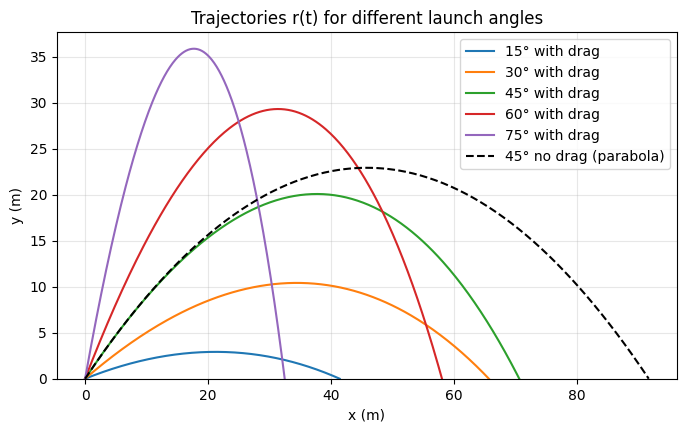

In [5]:
fig, ax = plt.subplots()
for deg in [15, 30, 45, 60, 75]:
    th = np.radians(deg)
    ts = np.linspace(0, flight_time(K, th), 300)
    ax.plot(X(ts, K, th), Y(ts, K, th), label=f"{deg}° with drag")

ts0 = np.linspace(0, flight_time(0), 300)
ax.plot(V0 * np.cos(TH) * ts0, V0 * np.sin(TH) * ts0 - 0.5 * G * ts0**2,
        "k--", label="45° no drag (parabola)")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Trajectories r(t) for different launch angles")
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

**Observation:** air resistance shortens the flight and makes the path **asymmetric**. The descent is steeper than the ascent, so the curve is no longer a parabola.

## 3. Limits and continuity

### 3.1 Limits at infinity – terminal velocity
What happens if the projectile could keep falling forever? We take $t \to \infty$:

In [6]:
lim_vx = sp.limit(v_vec[0], t, sp.oo)
lim_vy = sp.limit(v_vec[1], t, sp.oo)
lim_x = sp.limit(x_expr, t, sp.oo)

display(Math(r"\lim_{t\to\infty} v_x(t) = " + sp.latex(lim_vx)))
display(Math(r"\lim_{t\to\infty} v_y(t) = " + sp.latex(lim_vy) + r"\quad\text{(terminal velocity)}"))
display(Math(r"\lim_{t\to\infty} x(t) = " + sp.latex(lim_x) + r"\quad\text{(horizontal asymptote)}"))
print(f"Numerically: terminal velocity = {-G/K:.2f} m/s, "
      f"x can never exceed {V0*np.cos(TH)/K:.2f} m")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Numerically: terminal velocity = -98.10 m/s, x can never exceed 212.13 m


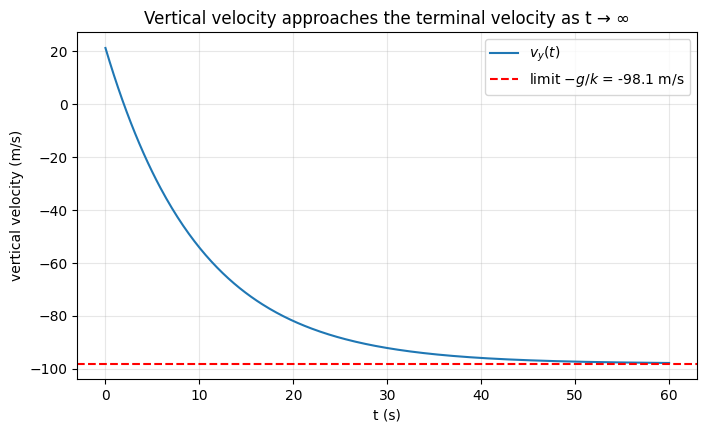

In [7]:
ts = np.linspace(0, 60, 400)
fig, ax = plt.subplots()
ax.plot(ts, VY(ts), label="$v_y(t)$")
ax.axhline(-G / K, color="r", ls="--", label=f"limit $-g/k$ = {-G/K:.1f} m/s")
ax.set(xlabel="t (s)", ylabel="vertical velocity (m/s)",
       title="Vertical velocity approaches the terminal velocity as t → ∞")
ax.legend()
plt.show()

### 3.2 A 0/0 limit – recovering the no-drag model
At $k = 0$ the formula for $x(t)$ has the form $\frac{0}{0}$, so it is **undefined**. Its limit as $k \to 0^+$ should still give back the ordinary parabola:

In [8]:
lim_x_k0 = sp.limit(x_expr, k, 0, dir="+")
lim_y_k0 = sp.limit(y_expr, k, 0, dir="+")
display(Math(r"\lim_{k\to 0^+} x(t) = " + sp.latex(sp.simplify(lim_x_k0))))
display(Math(r"\lim_{k\to 0^+} y(t) = " + sp.latex(sp.expand(lim_y_k0))))

# Numerical table: x(t=2 s) as k shrinks
print("\n      k        x(2; k)     no-drag x(2)")
for kk in [1, 0.1, 0.01, 0.001, 1e-4, 1e-6]:
    print(f"{kk:9.0e}   {X(2.0, kk):10.6f}   {V0*np.cos(TH)*2:10.6f}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>


      k        x(2; k)     no-drag x(2)
    1e+00    18.342309    42.426407
    1e-01    38.453014    42.426407
    1e-02    42.004957    42.426407
    1e-03    42.384009    42.426407
    1e-04    42.422165    42.426407
    1e-06    42.426364    42.426407


### 3.3 Continuity
**(a) Removable discontinuity in $k$.** Viewed as a function of $k$, $x(t;k)$ is undefined at $k = 0$, but the limit exists. Defining
$$\tilde x(t;k) = \begin{cases} \dfrac{u}{k}\left(1-e^{-kt}\right) & k>0 \\[4pt] u\,t & k = 0\end{cases}$$
removes the discontinuity: $\lim_{k\to0^+}\tilde x = \tilde x(t;0)$, so $\tilde x$ is continuous at $k=0$.

**(b) Landing: continuous but not differentiable.** After landing the projectile stays on the ground, so the height function is piecewise:
$$h(t) = \begin{cases} y(t) & 0 \le t \le T \\ 0 & t > T \end{cases}$$
We check continuity at $t = T$ (the left and right limits equal $h(T)$) and then compare the left and right derivatives.

In [9]:
T = T_FLIGHT
def h(tt):
    return np.where(tt <= T, Y(np.minimum(tt, T)), 0.0)

for eps in [1e-2, 1e-4, 1e-6]:
    print(f"eps={eps:.0e}:  h(T-eps) = {float(h(T-eps)):+.2e},  h(T+eps) = {float(h(T+eps)):+.2e}")
print(f"h(T) = {float(h(T)):+.2e}  ->  left limit = right limit = h(T): h is continuous at T")

eps = 1e-6
left_deriv = (float(h(T)) - float(h(T - eps))) / eps
right_deriv = (float(h(T + eps)) - float(h(T))) / eps
print(f"\nLeft derivative  ≈ {left_deriv:.4f} m/s  (= v_y(T) = {VY(T):.4f})")
print(f"Right derivative ≈ {right_deriv:.4f} m/s")
print("Left and right derivatives differ  ->  h is NOT differentiable at T (the impact).")

eps=1e-02:  h(T-eps) = +1.85e-01,  h(T+eps) = +0.00e+00
eps=1e-04:  h(T-eps) = +1.85e-03,  h(T+eps) = +0.00e+00
eps=1e-06:  h(T-eps) = +1.85e-05,  h(T+eps) = +0.00e+00
h(T) = +5.68e-14  ->  left limit = right limit = h(T): h is continuous at T

Left derivative  ≈ -18.5362 m/s  (= v_y(T) = -18.5362)
Right derivative ≈ -0.0000 m/s
Left and right derivatives differ  ->  h is NOT differentiable at T (the impact).


## 4. Differentiation

### 4.1 The derivative from first principles
$$y'(t) = \lim_{h\to 0}\frac{y(t+h)-y(t)}{h}.$$
We evaluate the difference quotient for shrinking $h$ at $t = 1\,$s and compare it with the exact derivative from SymPy.

In [10]:
t1 = 1.0
exact = VY(t1)
print("       h        difference quotient      error")
for hh in [1, 0.1, 0.01, 1e-3, 1e-4, 1e-5]:
    dq = (Y(t1 + hh) - Y(t1)) / hh
    print(f"{hh:9.0e}     {dq:16.10f}     {abs(dq - exact):.2e}")
print(f"Exact y'(1) = {exact:.10f} m/s")

       h        difference quotient      error
    1e+00         4.6366203329     5.22e+00
    1e-01         9.3210505078     5.38e-01
    1e-02         9.8050893975     5.40e-02
    1e-03         9.8536531616     5.40e-03
    1e-04         9.8585111398     5.40e-04
    1e-05         9.8589969497     5.40e-05
Exact y'(1) = 9.8590509343 m/s


### 4.2 Derivatives of exponential, trigonometric and logarithmic functions
* **Exponential:** $\frac{d}{dt}e^{-kt} = -k e^{-kt}$ gives $v_x = u e^{-kt}$ and $a_x = -ku e^{-kt}$.
* **Trigonometric:** differentiating the position with respect to the launch angle uses $\frac{d}{d\theta}\cos\theta = -\sin\theta$ and $\frac{d}{d\theta}\sin\theta = \cos\theta$.
* **Logarithmic:** solving $v_y(t)=0$ requires a logarithm, and its derivative uses $\frac{d}{dx}\ln f(x) = \frac{f'(x)}{f(x)}$.

In [11]:
display(Math(r"\frac{\partial x}{\partial t} = " + sp.latex(sp.diff(x_expr, t))))
display(Math(r"\frac{\partial x}{\partial \theta} = " + sp.latex(sp.diff(x_expr, theta))))
display(Math(r"\frac{\partial y}{\partial \theta} = " + sp.latex(sp.simplify(sp.diff(y_expr, theta)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 4.3 Time to the highest point and maximum height
At the top, the vertical velocity is zero: $v_y(t^*) = 0$. Solving gives a **logarithmic** formula:

In [12]:
t_peak_expr = sp.solve(sp.Eq(v_vec[1], 0), t)[0]
t_peak_expr = sp.simplify(t_peak_expr)
display(Math(r"t^* = " + sp.latex(t_peak_expr)))

H_expr = sp.simplify(y_expr.subs(t, t_peak_expr))
display(Math(r"H = y(t^*) = " + sp.latex(H_expr)))

t_peak_num = to_numeric(t_peak_expr)
H_num = to_numeric(H_expr)
T_PEAK = float(t_peak_num(0, K, G, V0, TH))
H_MAX = float(H_num(0, K, G, V0, TH))
print(f"t* = {T_PEAK:.4f} s,  H = {H_MAX:.4f} m")
print(f"Note: t* = {T_PEAK:.3f} s is less than half the flight time T/2 = {T_FLIGHT/2:.3f} s (asymmetric path)")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

t* = 1.9576 s,  H = 20.0869 m
Note: t* = 1.958 s is less than half the flight time T/2 = 2.026 s (asymmetric path)


In [13]:
# Derivative of the logarithmic peak-time formula with respect to the angle (chain rule)
dtpeak_dtheta = sp.simplify(sp.diff(t_peak_expr, theta))
display(Math(r"\frac{dt^*}{d\theta} = " + sp.latex(dtpeak_dtheta)))

dtp = to_numeric(dtpeak_dtheta)
hh = 1e-6
fd = (t_peak_num(0, K, G, V0, TH + hh) - t_peak_num(0, K, G, V0, TH - hh)) / (2 * hh)
print(f"Symbolic dt*/dθ = {float(dtp(0, K, G, V0, TH)):.6f} s/rad,  finite difference = {fd:.6f} s/rad")

<IPython.core.display.Math object>

Symbolic dt*/dθ = 1.777943 s/rad,  finite difference = 1.777943 s/rad


### 4.4 Optimisation: the best launch angle
**Without drag** the range is $R(\theta) = \dfrac{v_0^2 \sin 2\theta}{g}$. We set $R'(\theta)=0$ and use the second-derivative test.

In [14]:
R0_expr = v0**2 * sp.sin(2 * theta) / g
dR0 = sp.diff(R0_expr, theta)
d2R0 = sp.diff(R0_expr, theta, 2)
crit = sp.solve(sp.Eq(dR0, 0), theta)
crit = [c for c in crit if 0 < c < sp.pi / 2]
display(Math(r"R'(\theta) = " + sp.latex(dR0) + r",\qquad R''(\theta) = " + sp.latex(d2R0)))
for c in crit:
    print(f"Critical angle θ = {sp.deg(c)}°,  R''(θ) = {sp.simplify(d2R0.subs(theta, c))}  (< 0  ->  maximum)")

<IPython.core.display.Math object>

Critical angle θ = 45°,  R''(θ) = -4*v_0**2/g  (< 0  ->  maximum)


**With drag**, $R(\theta) = x(T(\theta), \theta)$ depends on the flight time, which has no closed form. We estimate $R'(\theta)$ with a central difference and find where it is zero.

Optimal angle with drag: 41.377°  ->  maximum range 71.205 m
Optimal angle without drag: 45°  ->  maximum range 91.743 m


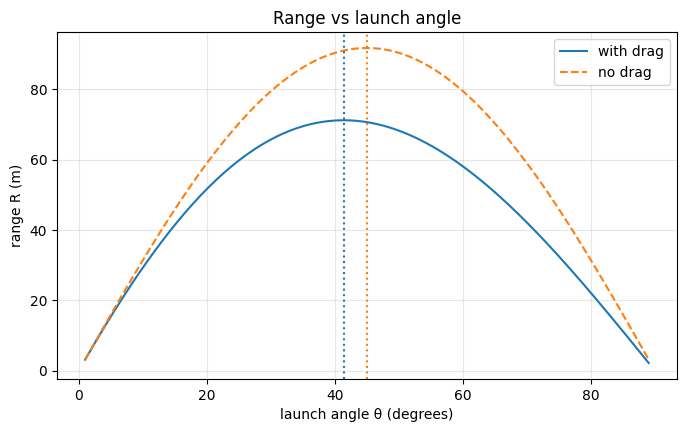

In [15]:
def dR_dtheta(th, hh=1e-5):
    return (landing_range(K, th + hh) - landing_range(K, th - hh)) / (2 * hh)

TH_OPT = optimize.brentq(dR_dtheta, np.radians(20), np.radians(60))
R_OPT = landing_range(K, TH_OPT)
print(f"Optimal angle with drag: {np.degrees(TH_OPT):.3f}°  ->  maximum range {R_OPT:.3f} m")
print(f"Optimal angle without drag: 45°  ->  maximum range {V0**2/G:.3f} m")

degs = np.linspace(1, 89, 300)
fig, ax = plt.subplots()
ax.plot(degs, [landing_range(K, np.radians(d)) for d in degs], label="with drag")
ax.plot(degs, [landing_range(0, np.radians(d)) for d in degs], "--", label="no drag")
ax.axvline(np.degrees(TH_OPT), color="C0", ls=":")
ax.axvline(45, color="C1", ls=":")
ax.set(xlabel="launch angle θ (degrees)", ylabel="range R (m)", title="Range vs launch angle")
ax.legend()
plt.show()

## 5. Vectors: speed, direction and the effect of acceleration

For the velocity $\mathbf v$ and acceleration $\mathbf a$:
* speed $= \lVert\mathbf v\rVert = \sqrt{v_x^2+v_y^2}$, and the unit tangent is $\hat{\mathbf T} = \mathbf v / \lVert\mathbf v\rVert$
* angle between them: $\cos\varphi = \dfrac{\mathbf a\cdot\mathbf v}{\lVert\mathbf a\rVert\,\lVert\mathbf v\rVert}$
* the **projection** of $\mathbf a$ onto $\mathbf v$, $a_T = \mathbf a\cdot\hat{\mathbf T}$, equals $\frac{d}{dt}\lVert\mathbf v\rVert$. If $a_T<0$ the projectile slows down, and if $a_T>0$ it speeds up.

In [16]:
def vector_report(tt):
    r = np.array([X(tt), Y(tt)])
    v = np.array([VX(tt), VY(tt)])
    a = np.array([AX(tt), AY(tt)])
    speed = np.linalg.norm(v)
    T_hat = v / speed
    a_T = a @ T_hat                          # tangential component (projection)
    a_N = np.linalg.norm(a - a_T * T_hat)    # normal component
    phi = np.degrees(np.arccos(a @ v / (np.linalg.norm(a) * speed)))
    return r, v, a, speed, T_hat, a_T, a_N, phi

for tt in [0.5, T_PEAK, T_FLIGHT - 0.3]:
    r, v, a, speed, T_hat, a_T, a_N, phi = vector_report(tt)
    trend = "slowing down" if a_T < 0 else "speeding up"
    print(f"t = {tt:5.3f} s | r = {r} | v = {v} | |v| = {speed:6.3f} m/s | "
          f"angle(a, v) = {phi:6.2f}° | a_T = {a_T:+.3f} ({trend})")

# Check: tangential acceleration equals d|v|/dt
tt, hh = 1.0, 1e-6
speed_rate = (np.hypot(VX(tt + hh), VY(tt + hh)) - np.hypot(VX(tt - hh), VY(tt - hh))) / (2 * hh)
print(f"\nAt t = 1 s:  a·T̂ = {vector_report(tt)[5]:.6f},  d|v|/dt (numerical) = {speed_rate:.6f}")

t = 0.500 s | r = [10.345801  9.139736] | v = [20.178623 15.39423 ] | |v| = 25.380 m/s | angle(a, v) = 137.42° | a_T = -8.488 (slowing down)
t = 1.958 s | r = [37.715859 20.086932] | v = [17.441618  0.      ] | |v| = 17.442 m/s | angle(a, v) = 100.08° | a_T = -1.744 (slowing down)
t = 3.752 s | r = [66.363999  5.199204] | v = [ 14.576804 -16.113084] | |v| = 21.728 m/s | angle(a, v) =  52.22° | a_T = +5.102 (speeding up)

At t = 1 s:  a·T̂ = -6.639968,  d|v|/dt (numerical) = -6.639968


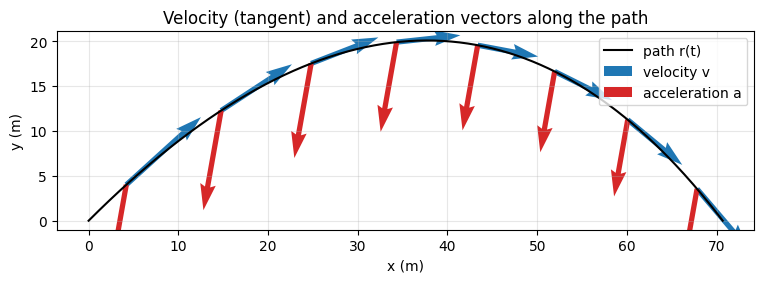

In [17]:
ts = np.linspace(0, T_FLIGHT, 300)
tq = np.linspace(0.2, T_FLIGHT - 0.2, 8)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(X(ts), Y(ts), "k", lw=1.5, label="path r(t)")
ax.quiver(X(tq), Y(tq), VX(tq), VY(tq), color="C0", angles="xy", scale_units="xy", scale=2.5, label="velocity v")
ax.quiver(X(tq), Y(tq), AX(tq), AY(tq), color="C3", angles="xy", scale_units="xy", scale=1.0, label="acceleration a")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Velocity (tangent) and acceleration vectors along the path")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.show()

## 6. Newton's method, Rolle's theorem and the Mean Value Theorem

### 6.1 Finding the flight time with Newton's method
Newton's method uses the derivative to solve $y(T) = 0$:
$$T_{n+1} = T_n - \frac{y(T_n)}{y'(T_n)} = T_n - \frac{y(T_n)}{v_y(T_n)} .$$
We start from the drag-free flight time.

In [18]:
def newton(f, df, x0, tol=1e-12, max_iter=50, verbose=True):
    x = x0
    for i in range(max_iter):
        step = f(x) / df(x)
        x -= step
        if verbose:
            print(f"iter {i+1}:  T = {x:.12f}   |step| = {abs(step):.2e}")
        if abs(step) < tol:
            return x
    raise RuntimeError("Newton's method did not converge")

T_newton = newton(Y, VY, flight_time(0))
print(f"\nNewton: T = {T_newton:.12f} s   SciPy brentq: T = {T_FLIGHT:.12f} s")

iter 1:  T = 4.065992043181   |step| = 2.59e-01
iter 2:  T = 4.051965445164   |step| = 1.40e-02
iter 3:  T = 4.051923260482   |step| = 4.22e-05
iter 4:  T = 4.051923260100   |step| = 3.82e-10
iter 5:  T = 4.051923260100   |step| = 6.13e-15

Newton: T = 4.051923260100 s   SciPy brentq: T = 4.051923260100 s


### 6.2 Rolle's theorem – a highest point must exist
**Rolle's theorem:** if $f$ is continuous on $[a,b]$, differentiable on $(a,b)$ and $f(a)=f(b)$, then there is some $c\in(a,b)$ with $f'(c)=0$.

For $y(t)$ on $[0, T]$:
1. $y$ is built from $e^{-kt}$ and polynomials, so it is **continuous** on $[0,T]$ ✔
2. it is **differentiable** on $(0,T)$ ✔
3. $y(0) = y(T) = 0$ ✔

So there **must** be a time $c$ with $y'(c) = v_y(c) = 0$: the highest point. We find $c$ numerically and compare it with the logarithmic formula from Section 4.3.

In [19]:
print(f"Hypotheses: y(0) = {Y(0.0):.2e},  y(T) = {Y(T_FLIGHT):.2e}")
c_rolle = optimize.brentq(VY, 1e-9, T_FLIGHT)
print(f"Rolle point c (numerical root of y') = {c_rolle:.10f} s")
print(f"Formula t* = ln(1 + k v0 sinθ / g) / k = {T_PEAK:.10f} s")

Hypotheses: y(0) = 0.00e+00,  y(T) = 5.68e-14
Rolle point c (numerical root of y') = 1.9576463064 s
Formula t* = ln(1 + k v0 sinθ / g) / k = 1.9576463064 s


### 6.3 Mean Value Theorem (Rolle's theorem generalised)
For $x(t)$ on $[0,T]$ there is a $c$ where the **instantaneous** horizontal speed equals the **average** horizontal speed:
$$v_x(c) = \frac{x(T)-x(0)}{T-0}.$$
Because $v_x(c) = u e^{-kc}$, we can solve exactly with a logarithm: $c = -\frac1k\ln\!\left(\frac{x(T)}{uT}\right)$.

Average horizontal speed = 17.441618 m/s
MVT point c = 1.957646 s, where v_x(c) = 17.441618 m/s


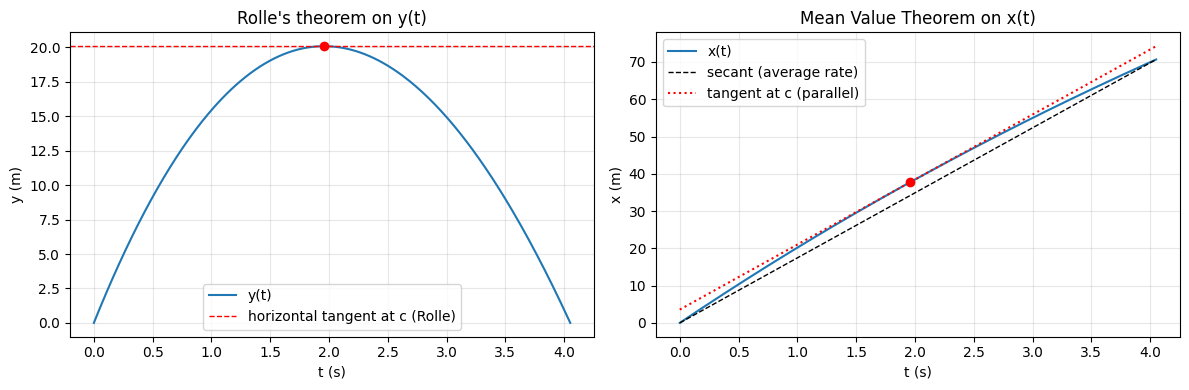

In [20]:
avg_vx = X(T_FLIGHT) / T_FLIGHT
c_mvt = -np.log(avg_vx / (V0 * np.cos(TH))) / K
print(f"Average horizontal speed = {avg_vx:.6f} m/s")
print(f"MVT point c = {c_mvt:.6f} s, where v_x(c) = {VX(c_mvt):.6f} m/s")

ts = np.linspace(0, T_FLIGHT, 300)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(ts, Y(ts), label="y(t)")
axs[0].axhline(H_MAX, color="r", ls="--", lw=1, label="horizontal tangent at c (Rolle)")
axs[0].plot(c_rolle, H_MAX, "ro")
axs[0].set(xlabel="t (s)", ylabel="y (m)", title="Rolle's theorem on y(t)")
axs[0].legend()
axs[1].plot(ts, X(ts), label="x(t)")
axs[1].plot([0, T_FLIGHT], [0, X(T_FLIGHT)], "k--", lw=1, label="secant (average rate)")
axs[1].plot(ts, X(c_mvt) + avg_vx * (ts - c_mvt), "r:", label="tangent at c (parallel)")
axs[1].plot(c_mvt, X(c_mvt), "ro")
axs[1].set(xlabel="t (s)", ylabel="x (m)", title="Mean Value Theorem on x(t)")
axs[1].legend()
plt.tight_layout()
plt.show()

## 7. Leibniz's rule

### 7.1 Leibniz's theorem for the nth derivative of a product
$$\frac{d^n}{dt^n}\big(u\,v\big) = \sum_{r=0}^{n}\binom{n}{r}\,u^{(r)}\,v^{(n-r)} .$$

**Classic example.** For $f(t) = t^2e^{-kt}$ only three terms survive, because $(t^2)^{(r)} = 0$ for $r\ge 3$:
$$f^{(n)}(t) = e^{-kt}\Big[(-k)^n t^2 + 2n(-k)^{n-1}t + n(n-1)(-k)^{n-2}\Big].$$

In [21]:
def leibniz_nth(u_, v_, var, n):
    return sum(sp.binomial(n, r) * sp.diff(u_, var, r) * sp.diff(v_, var, n - r) for r in range(n + 1))

n = sp.Symbol("n")
closed_form = sp.exp(-k*t) * ((-k)**n * t**2 + 2*n*(-k)**(n-1) * t + n*(n-1)*(-k)**(n-2))
for nn in range(1, 7):
    lhs = leibniz_nth(t**2, sp.exp(-k*t), t, nn)
    direct = sp.diff(t**2 * sp.exp(-k*t), t, nn)
    formula = closed_form.subs(n, nn)
    print(f"n = {nn}:  Leibniz == direct: {sp.simplify(lhs - direct) == 0},  "
          f"closed form == direct: {sp.simplify(formula - direct) == 0}")

n = 1:  Leibniz == direct: True,  closed form == direct: True
n = 2:  Leibniz == direct: True,  closed form == direct: True
n = 3:  Leibniz == direct: True,  closed form == direct: True
n = 4:  Leibniz == direct: True,  closed form == direct: True
n = 5:  Leibniz == direct: True,  closed form == direct: True
n = 6:  Leibniz == direct: True,  closed form == direct: True


**Applied to the projectile.** The rate of change of $\tfrac12 x^2$ is the product $x(t)\,v_x(t)$. Its higher derivatives come straight from Leibniz's theorem using the derivatives of $x$ and $v_x$:

In [22]:
product = x_expr * v_vec[0]
for nn in range(1, 6):
    via_leibniz = leibniz_nth(x_expr, v_vec[0], t, nn)
    direct = sp.diff(product, t, nn)
    print(f"n = {nn}:  Leibniz's theorem agrees with direct differentiation: {sp.simplify(via_leibniz - direct) == 0}")

display(Math(r"\frac{d^3}{dt^3}\big(x\,v_x\big) = " + sp.latex(sp.factor(sp.simplify(leibniz_nth(x_expr, v_vec[0], t, 3))))))

n = 1:  Leibniz's theorem agrees with direct differentiation: True
n = 2:  Leibniz's theorem agrees with direct differentiation: True
n = 3:  Leibniz's theorem agrees with direct differentiation: True
n = 4:  Leibniz's theorem agrees with direct differentiation: True
n = 5:  Leibniz's theorem agrees with direct differentiation: True


<IPython.core.display.Math object>

### 7.2 Leibniz's rule for differentiating an integral – sensitivity to drag
The range is an integral whose **upper limit also depends on $k$**:
$$R(k) = \int_0^{T(k)} v_x(t;k)\,dt .$$
Leibniz's integral rule gives
$$\frac{dR}{dk} = v_x\big(T(k);k\big)\,T'(k) + \int_0^{T(k)} \frac{\partial v_x}{\partial k}\,dt,$$
and $T'(k)$ comes from implicit differentiation of $y(T(k);k) = 0$:
$$T'(k) = -\frac{\partial y/\partial k}{\partial y/\partial t}\bigg|_{t=T}.$$

In [23]:
dvx_dk = to_numeric(sp.diff(v_vec[0], k))
dy_dk = to_numeric(sp.diff(y_expr, k))

T_prime = -dy_dk(T_FLIGHT, K, G, V0, TH) / VY(T_FLIGHT)
boundary_term = VX(T_FLIGHT) * T_prime
interior_term, _ = integrate.quad(lambda tt: dvx_dk(tt, K, G, V0, TH), 0, T_FLIGHT)
dR_dk = boundary_term + interior_term

hh = 1e-6
T_prime_fd = (flight_time(K + hh) - flight_time(K - hh)) / (2 * hh)
dR_dk_fd = (landing_range(K + hh) - landing_range(K - hh)) / (2 * hh)

print(f"T'(k):  implicit differentiation = {T_prime:.6f},  finite difference = {T_prime_fd:.6f}")
print(f"Boundary term  v_x(T) T'(k)      = {boundary_term:.6f}")
print(f"Interior term  ∫ ∂v_x/∂k dt       = {interior_term:.6f}")
print(f"dR/dk (Leibniz rule)             = {dR_dk:.6f} m per (1/s)")
print(f"dR/dk (finite difference check)  = {dR_dk_fd:.6f}")
print(f"\nInterpretation: increasing k by 0.01 changes the range by about {0.01*dR_dk:.3f} m.")

T'(k):  implicit differentiation = -2.392630,  finite difference = -2.392630
Boundary term  v_x(T) T'(k)      = -33.846124
Interior term  ∫ ∂v_x/∂k dt       = -133.536140
dR/dk (Leibniz rule)             = -167.382264 m per (1/s)
dR/dk (finite difference check)  = -167.382264

Interpretation: increasing k by 0.01 changes the range by about -1.674 m.


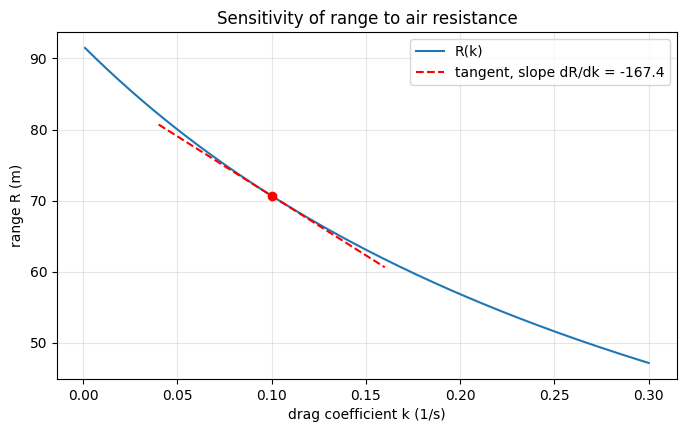

In [24]:
ks = np.linspace(0.001, 0.3, 200)
Rk = [landing_range(kk) for kk in ks]
fig, ax = plt.subplots()
ax.plot(ks, Rk, label="R(k)")
kt = np.linspace(K - 0.06, K + 0.06, 10)
ax.plot(kt, landing_range(K) + dR_dk * (kt - K), "r--", label=f"tangent, slope dR/dk = {dR_dk:.1f}")
ax.plot(K, landing_range(K), "ro")
ax.set(xlabel="drag coefficient k (1/s)", ylabel="range R (m)", title="Sensitivity of range to air resistance")
ax.legend()
plt.show()

## 8. Integration: exact results, the trapezium rule and Simpson's rule

### 8.1 Exact integration and the Fundamental Theorem of Calculus
The horizontal distance is the integral of the horizontal velocity: $\displaystyle x(t) = \int_0^t v_x(s)\,ds$.

In [25]:
s = sp.Symbol("s", positive=True)
x_from_integral = sp.integrate(v_vec[0].subs(t, s), (s, 0, t))
display(Math(r"\int_0^t v_x(s)\,ds = " + sp.latex(sp.simplify(x_from_integral))))
print("Equal to x(t)?", sp.simplify(x_from_integral - x_expr) == 0)

<IPython.core.display.Math object>

Equal to x(t)? True


### 8.2 Implementing the numerical rules
With $n$ strips of width $h = (b-a)/n$:

* **Trapezium rule:** $\displaystyle \int_a^b f\,dx \approx \frac{h}{2}\Big[f_0 + 2(f_1+\dots+f_{n-1}) + f_n\Big]$, with error $O(h^2)$
* **Simpson's rule** ($n$ even): $\displaystyle \int_a^b f\,dx \approx \frac{h}{3}\Big[f_0 + 4(f_1+f_3+\dots) + 2(f_2+f_4+\dots) + f_n\Big]$, with error $O(h^4)$

In [26]:
def trapezium(f, a, b, n):
    xs = np.linspace(a, b, n + 1)
    ys = f(xs)
    h = (b - a) / n
    return h / 2 * (ys[0] + 2 * ys[1:-1].sum() + ys[-1])

def simpson(f, a, b, n):
    if n % 2:
        raise ValueError("Simpson's rule needs an even number of strips")
    xs = np.linspace(a, b, n + 1)
    ys = f(xs)
    h = (b - a) / n
    return h / 3 * (ys[0] + 4 * ys[1:-1:2].sum() + 2 * ys[2:-1:2].sum() + ys[-1])

# Validate on integrals with known answers
tests = [("∫_0^π sin x dx", np.sin, 0, np.pi, 2.0),
         ("∫_1^e (ln x)/x dx", lambda x: np.log(x) / x, 1, np.e, 0.5),
         ("∫_0^1 e^x dx", np.exp, 0, 1, np.e - 1)]
print(f"{'integral':20s} {'exact':>10s} {'trapezium (n=10)':>18s} {'Simpson (n=10)':>16s}")
for name, f, a, b, exact in tests:
    print(f"{name:20s} {exact:10.6f} {trapezium(f, a, b, 10):18.8f} {simpson(f, a, b, 10):16.8f}")

integral                  exact   trapezium (n=10)   Simpson (n=10)
∫_0^π sin x dx         2.000000         1.98352354       2.00010952
∫_1^e (ln x)/x dx      0.500000         0.49755257       0.49995126
∫_0^1 e^x dx           1.718282         1.71971349       1.71828278


### 8.3 Applying the rules to the projectile
| Quantity | Integral |
|---|---|
| Range | $R = \displaystyle\int_0^T v_x\,dt$ (exact value known: $x(T)$) |
| Path (arc) length | $L = \displaystyle\int_0^T \lVert\mathbf v(t)\rVert\,dt = \int_0^T\sqrt{v_x^2+v_y^2}\,dt$ (no elementary antiderivative) |
| Area under the path | $A = \displaystyle\int_0^R y\,dx = \int_0^T y(t)\,v_x(t)\,dt$ (substitution $x = x(t)$, $dx = v_x\,dt$) |

In [27]:
speed = lambda tt: np.hypot(VX(tt), VY(tt))
area_integrand = lambda tt: Y(tt) * VX(tt)

R_exact = X(T_FLIGHT)
L_ref, _ = integrate.quad(speed, 0, T_FLIGHT, epsabs=1e-13, epsrel=1e-13)
A_ref, _ = integrate.quad(area_integrand, 0, T_FLIGHT, epsabs=1e-13, epsrel=1e-13)

rows = [("Range R (m)", VX, R_exact), ("Arc length L (m)", speed, L_ref), ("Area A (m²)", area_integrand, A_ref)]
print(f"{'quantity':18s} {'reference':>12s} {'trapezium n=20':>15s} {'Simpson n=20':>14s}")
for name, f, ref in rows:
    print(f"{name:18s} {ref:12.6f} {trapezium(f, 0, T_FLIGHT, 20):15.6f} {simpson(f, 0, T_FLIGHT, 20):14.6f}")
print(f"\nThe path is {L_ref - R_exact:.2f} m longer than the horizontal range.")

quantity              reference  trapezium n=20   Simpson n=20
Range R (m)           70.672096       70.674513      70.672096
Arc length L (m)      83.862665       83.915357      83.862641
Area A (m²)          945.960025      943.524131     945.959299

The path is 13.19 m longer than the horizontal range.


### 8.4 Error analysis: how fast does each rule converge?
If the error behaves like $C h^p$, a log–log plot of error against $n$ is a straight line with slope $-p$. Theory predicts $p=2$ for the trapezium rule and $p=4$ for Simpson's rule.

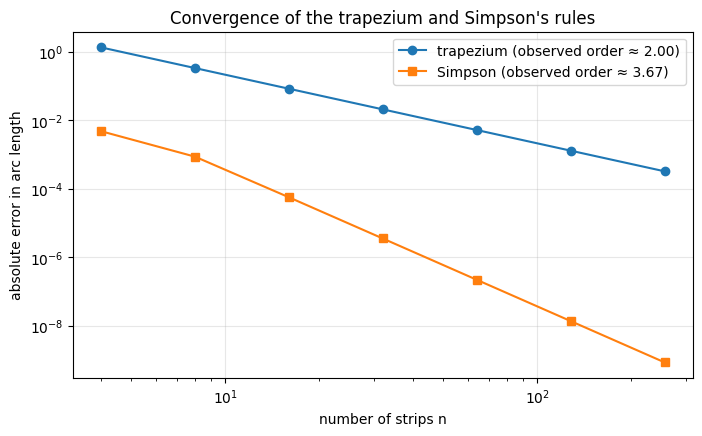

n =    4   trapezium error = 1.321e+00   Simpson error = 4.757e-03
n =    8   trapezium error = 3.295e-01   Simpson error = 8.612e-04
n =   16   trapezium error = 8.234e-02   Simpson error = 5.640e-05
n =   32   trapezium error = 2.058e-02   Simpson error = 3.541e-06
n =   64   trapezium error = 5.145e-03   Simpson error = 2.215e-07
n =  128   trapezium error = 1.286e-03   Simpson error = 1.385e-08
n =  256   trapezium error = 3.216e-04   Simpson error = 8.656e-10


In [28]:
ns = np.array([4, 8, 16, 32, 64, 128, 256])
err_trap = np.array([abs(trapezium(speed, 0, T_FLIGHT, n_) - L_ref) for n_ in ns])
err_simp = np.array([abs(simpson(speed, 0, T_FLIGHT, n_) - L_ref) for n_ in ns])

p_trap = -np.polyfit(np.log(ns), np.log(err_trap), 1)[0]
p_simp = -np.polyfit(np.log(ns[:5]), np.log(err_simp[:5]), 1)[0]

fig, ax = plt.subplots()
ax.loglog(ns, err_trap, "o-", label=f"trapezium (observed order ≈ {p_trap:.2f})")
ax.loglog(ns, err_simp, "s-", label=f"Simpson (observed order ≈ {p_simp:.2f})")
ax.set(xlabel="number of strips n", ylabel="absolute error in arc length",
       title="Convergence of the trapezium and Simpson's rules")
ax.legend()
plt.show()

for n_, et, es in zip(ns, err_trap, err_simp):
    print(f"n = {n_:4d}   trapezium error = {et:.3e}   Simpson error = {es:.3e}")

## 9. Systems of equations and matrices: estimating gravity from data

Without drag, the path is the parabola
$$y = \tan\theta\; x - \frac{g}{2v_0^2\cos^2\theta}\,x^2 \quad\Longrightarrow\quad y = a + bx + cx^2,\qquad g = -2c\,v_0^2\cos^2\theta.$$
If we can find $c$ from position measurements (for example from tracking a video), we can **estimate $g$**.

### 9.1 Exact fit through three points: a 3×3 linear system
Three points $(x_i, y_i)$ give the system
$$\begin{pmatrix}1 & x_1 & x_1^2\\ 1 & x_2 & x_2^2\\ 1 & x_3 & x_3^2\end{pmatrix}\begin{pmatrix}a\\b\\c\end{pmatrix} = \begin{pmatrix}y_1\\y_2\\y_3\end{pmatrix}.$$
We solve it in four ways: our own Gaussian elimination, Cramer's rule, the matrix inverse, and NumPy.

In [29]:
def parabola_y(xx, th=TH):
    return np.tan(th) * xx - G / (2 * V0**2 * np.cos(th)**2) * xx**2

xs3 = np.array([10.0, 40.0, 70.0])
ys3 = parabola_y(xs3)
A3 = np.column_stack([np.ones(3), xs3, xs3**2])
print("Coefficient matrix A =\n", A3, "\nRight-hand side y =", ys3)

def gaussian_elimination(A, b):
    A, b = A.astype(float).copy(), b.astype(float).copy()
    n_ = len(b)
    for col in range(n_):
        p = col + np.argmax(np.abs(A[col:, col]))       # partial pivoting
        if np.isclose(A[p, col], 0):
            raise ValueError("Matrix is singular")
        A[[col, p]], b[[col, p]] = A[[p, col]], b[[p, col]]
        for row in range(col + 1, n_):
            m = A[row, col] / A[col, col]
            A[row, col:] -= m * A[col, col:]
            b[row] -= m * b[col]
    sol = np.zeros(n_)
    for i in range(n_ - 1, -1, -1):                     # back substitution
        sol[i] = (b[i] - A[i, i + 1:] @ sol[i + 1:]) / A[i, i]
    return sol

def cramer(A, b):
    D = np.linalg.det(A)
    if np.isclose(D, 0):
        raise ValueError("det(A) = 0: no unique solution")
    sol = []
    for i in range(len(b)):
        Ai = A.copy()
        Ai[:, i] = b
        sol.append(np.linalg.det(Ai) / D)
    return np.array(sol)

print(f"\ndet(A) = {np.linalg.det(A3):.2f}  (non-zero  ->  unique solution)")
methods = {"Gaussian elimination": gaussian_elimination(A3, ys3),
           "Cramer's rule": cramer(A3, ys3),
           "Inverse  A^-1 y": np.linalg.inv(A3) @ ys3,
           "numpy.linalg.solve": np.linalg.solve(A3, ys3)}
for name, (a_, b_, c_) in methods.items():
    print(f"{name:22s} a = {a_:+.6f}  b = {b_:+.6f}  c = {c_:+.8f}  ->  g = {-2*c_*V0**2*np.cos(TH)**2:.6f}")

Coefficient matrix A =
 [[   1.   10.  100.]
 [   1.   40. 1600.]
 [   1.   70. 4900.]] 
Right-hand side y = [ 8.91 22.56 16.59]

det(A) = 54000.00  (non-zero  ->  unique solution)
Gaussian elimination   a = +0.000000  b = +1.000000  c = -0.01090000  ->  g = 9.810000
Cramer's rule          a = +0.000000  b = +1.000000  c = -0.01090000  ->  g = 9.810000
Inverse  A^-1 y        a = +0.000000  b = +1.000000  c = -0.01090000  ->  g = 9.810000
numpy.linalg.solve     a = +0.000000  b = +1.000000  c = -0.01090000  ->  g = 9.810000


### 9.2 Noisy measurements: least squares with the normal equations
Real measurements contain noise, so we use many points and an **overdetermined** system $A\boldsymbol\beta \approx \mathbf y$. The best fit solves the **normal equations**
$$\big(A^{\mathsf T}A\big)\,\boldsymbol\beta = A^{\mathsf T}\mathbf y .$$

A^T A =
 [[2.000000e+01 9.000000e+02 5.228947e+04]
 [9.000000e+02 5.228947e+04 3.414079e+06]
 [5.228947e+04 3.414079e+06 2.377221e+08]]
det(A^T A) = 1.301e+12,  rank(A) = 3

Fitted: a = -0.1393, b = +1.0035 (tan θ = 1.0000), c = -0.010912
Estimated g = 9.821 m/s²   (true value 9.81, error 0.11 %)
Check with numpy.polyfit: [-0.139341  1.003518 -0.010912]


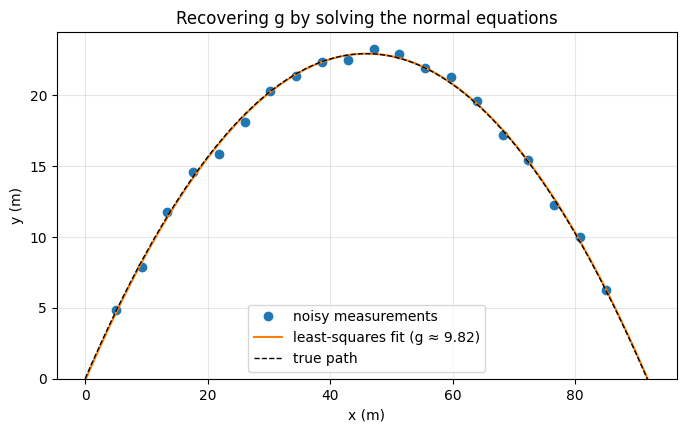

In [30]:
rng = np.random.default_rng(42)
x_data = np.linspace(5, 85, 20)
y_data = parabola_y(x_data) + rng.normal(0, 0.4, x_data.size)     # ±0.4 m measurement noise

A = np.column_stack([np.ones_like(x_data), x_data, x_data**2])
AtA, Aty = A.T @ A, A.T @ y_data
print("A^T A =\n", AtA)
print(f"det(A^T A) = {np.linalg.det(AtA):.3e},  rank(A) = {np.linalg.matrix_rank(A)}")

beta = gaussian_elimination(AtA, Aty)
g_est = -2 * beta[2] * V0**2 * np.cos(TH)**2
print(f"\nFitted: a = {beta[0]:+.4f}, b = {beta[1]:+.4f} (tan θ = {np.tan(TH):.4f}), c = {beta[2]:+.6f}")
print(f"Estimated g = {g_est:.3f} m/s²   (true value {G}, error {100*abs(g_est-G)/G:.2f} %)")
print("Check with numpy.polyfit:", np.polyfit(x_data, y_data, 2)[::-1])

xx = np.linspace(0, 92, 300)
fig, ax = plt.subplots()
ax.plot(x_data, y_data, "o", label="noisy measurements")
ax.plot(xx, beta[0] + beta[1] * xx + beta[2] * xx**2, label=f"least-squares fit (g ≈ {g_est:.2f})")
ax.plot(xx, parabola_y(xx), "k--", lw=1, label="true path")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Recovering g by solving the normal equations")
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

## 10. Inequalities: which launch angles are safe?

**Design task.** A wall of height $h_w = 10$ m stands $d = 40$ m from the launcher. The projectile must
1. **clear the wall:** $y(\text{at } x=d) \ge h_w$
2. **land in the target zone** $60 \le R \le 85$ m, which can be written as the absolute-value inequality $|R - 72.5| \le 12.5$.

### 10.1 No drag: solving the inequalities exactly
Put $s = \tan\theta$ and use $\sec^2\theta = 1 + s^2$. The wall condition becomes a **quadratic inequality** in $s$:
$$d\,s - \frac{g d^2}{2v_0^2}(1+s^2) \ \ge\ h_w .$$

In [31]:
D_WALL, H_WALL = 40.0, 10.0
R_LO, R_HI = 60.0, 85.0

s_sym = sp.Symbol("s", real=True)
G_r, V0_r = sp.Rational(str(G)), sp.Rational(str(V0))
d_r, h_r = sp.Rational(str(D_WALL)), sp.Rational(str(H_WALL))
wall_ineq = d_r * s_sym - G_r * d_r**2 / (2 * V0_r**2) * (1 + s_sym**2) - h_r >= 0
s_interval = sp.solve_univariate_inequality(wall_ineq, s_sym, relational=False)
display(Math(r"\text{Wall condition: } " + sp.latex(wall_ineq) + r"\;\Longrightarrow\; s=\tan\theta \in " + sp.latex(s_interval.evalf(6))))
wall_lo, wall_hi = np.degrees(np.arctan(float(s_interval.start))), np.degrees(np.arctan(float(s_interval.end)))
print(f"Clears the wall for  {wall_lo:.2f}° ≤ θ ≤ {wall_hi:.2f}°")

<IPython.core.display.Math object>

Clears the wall for  27.88° ≤ θ ≤ 76.16°


The landing condition $|R - 72.5|\le 12.5$ with $R = \frac{v_0^2}{g}\sin 2\theta$ is a **trigonometric inequality**:
$$\frac{gR_{lo}}{v_0^2} \le \sin 2\theta \le \frac{gR_{hi}}{v_0^2}, \qquad 0^\circ<\theta<90^\circ .$$
Because $\sin 2\theta$ rises and then falls on $(0^\circ, 90^\circ)$, the solution set is **two intervals**, symmetric about $45^\circ$.

In [32]:
lo, hi = G * R_LO / V0**2, G * R_HI / V0**2
print(f"{lo:.4f} ≤ sin 2θ ≤ {hi:.4f}")
a1, a2 = np.degrees(np.arcsin(lo)) / 2, np.degrees(np.arcsin(hi)) / 2
land_intervals = [(a1, a2), (90 - a2, 90 - a1)]
print("Lands in zone for θ ∈ " + " ∪ ".join(f"[{p:.2f}°, {q:.2f}°]" for p, q in land_intervals))

safe_nodrag = [(max(p, wall_lo), min(q, wall_hi)) for p, q in land_intervals if max(p, wall_lo) <= min(q, wall_hi)]
print("Both conditions (intersection): θ ∈ " + " ∪ ".join(f"[{p:.2f}°, {q:.2f}°]" for p, q in safe_nodrag))

0.6540 ≤ sin 2θ ≤ 0.9265
Lands in zone for θ ∈ [20.42°, 33.95°] ∪ [56.05°, 69.58°]
Both conditions (intersection): θ ∈ [27.88°, 33.95°] ∪ [56.05°, 69.58°]


### 10.2 With drag: inequalities that need numerical solution
With drag, the time at which the projectile reaches $x = d$ comes from solving $x(t) = d$:
$$t_d = -\frac1k\ln\!\left(1 - \frac{kd}{v_0\cos\theta}\right).$$
The logarithm only exists if its argument is positive. This gives the **domain inequality** $\cos\theta > \frac{kd}{v_0}$. For steeper angles the projectile **never reaches the wall** at all. We check every angle on a fine grid.

In [33]:
def height_at_wall(th, kk=K):
    arg = 1 - kk * D_WALL / (V0 * np.cos(th))
    if arg <= 0:
        return -np.inf                         # never reaches x = d
    t_d = -np.log(arg) / kk
    return Y(t_d, kk, th) if t_d <= flight_time(kk, th) else -np.inf

theta_max_domain = np.degrees(np.arccos(K * D_WALL / V0))
print(f"Domain condition cos θ > kd/v0  ->  θ < {theta_max_domain:.2f}°")

grid = np.arange(1, 89.001, 0.01)
clears = np.array([height_at_wall(np.radians(d_)) >= H_WALL for d_ in grid])
ranges = np.array([landing_range(K, np.radians(d_)) for d_ in grid])
in_zone = np.abs(ranges - (R_LO + R_HI) / 2) <= (R_HI - R_LO) / 2
safe = clears & in_zone

def to_intervals(mask):
    out, start = [], None
    for d_, ok in zip(grid, mask):
        if ok and start is None: start = d_
        if not ok and start is not None: out.append((start, prev)); start = None
        prev = d_
    if start is not None: out.append((start, prev))
    return out

fmt = lambda iv: " ∪ ".join(f"[{p:.2f}°, {q:.2f}°]" for p, q in iv) or "no solution"
print("Clears wall:       ", fmt(to_intervals(clears)))
print("Lands in zone:     ", fmt(to_intervals(in_zone)))
print("SAFE (both):       ", fmt(to_intervals(safe)))

Domain condition cos θ > kd/v0  ->  θ < 82.34°
Clears wall:        [29.83°, 69.57°]
Lands in zone:      [25.17°, 58.52°]
SAFE (both):        [29.83°, 58.52°]


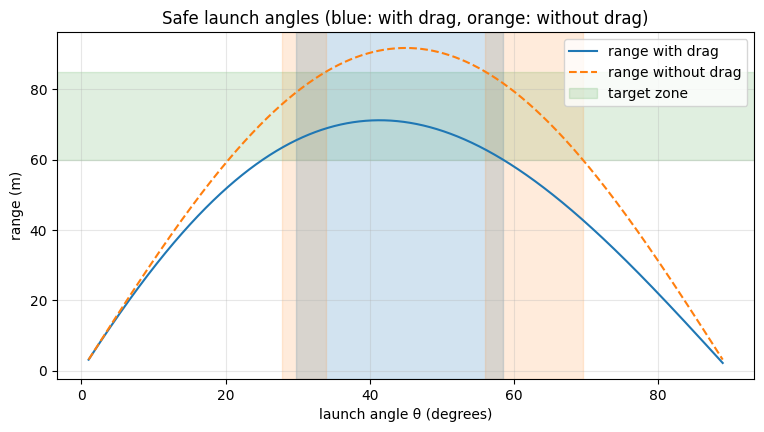

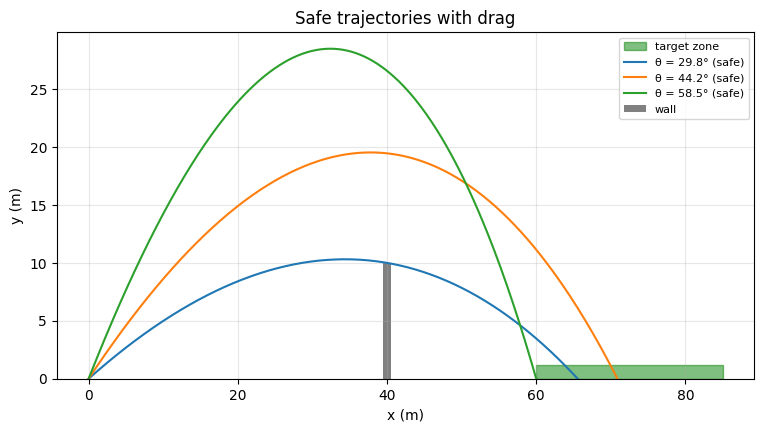

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(grid, ranges, label="range with drag")
ax.plot(grid, V0**2 * np.sin(2 * np.radians(grid)) / G, "--", label="range without drag")
ax.axhspan(R_LO, R_HI, color="green", alpha=0.12, label="target zone")
for p, q in to_intervals(safe):
    ax.axvspan(p, q, color="C0", alpha=0.2)
for p, q in safe_nodrag:
    ax.axvspan(p, q, color="C1", alpha=0.15)
ax.set(xlabel="launch angle θ (degrees)", ylabel="range (m)",
       title="Safe launch angles (blue: with drag, orange: without drag)")
ax.legend(loc="upper right")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(D_WALL, H_WALL, width=1.2, color="gray", label="wall")
ax.axvspan(R_LO, R_HI, ymax=0.04, color="green", alpha=0.5, label="target zone")
safe_ivs = to_intervals(safe)
for p, q in safe_ivs:
    for d_ in np.linspace(p, q, 3):
        th = np.radians(d_)
        ts = np.linspace(0, flight_time(K, th), 300)
        ax.plot(X(ts, K, th), Y(ts, K, th), label=f"θ = {d_:.1f}° (safe)")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Safe trajectories with drag")
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.show()

## 11. Results summary and conclusion

In [35]:
summary = {
    "Flight time T (s)": T_FLIGHT,
    "Time to peak t* (s)": T_PEAK,
    "Maximum height H (m)": H_MAX,
    "Range R (m)": X(T_FLIGHT),
    "Path length L (m)": L_ref,
    "Area under path A (m²)": A_ref,
    "Terminal velocity (m/s)": -G / K,
    "Best launch angle with drag (deg)": np.degrees(TH_OPT),
    "dR/dk (m per 1/s)": dR_dk,
    "g estimated from noisy data (m/s²)": g_est,
}
print(f"Scenario: v0 = {V0} m/s, θ = {THETA_DEG}°, k = {K} 1/s\n")
for key, val in summary.items():
    print(f"{key:38s} {val:10.4f}")

Scenario: v0 = 30.0 m/s, θ = 45.0°, k = 0.1 1/s

Flight time T (s)                          4.0519
Time to peak t* (s)                        1.9576
Maximum height H (m)                      20.0869
Range R (m)                               70.6721
Path length L (m)                         83.8627
Area under path A (m²)                   945.9600
Terminal velocity (m/s)                  -98.1000
Best launch angle with drag (deg)         41.3767
dR/dk (m per 1/s)                       -167.3823
g estimated from noisy data (m/s²)         9.8211


### Conclusion
This project showed that a single physical problem can bring together the whole Calculus I syllabus:

* **Vector functions** described the motion, and **differentiation** (exponential, trigonometric and logarithmic) gave velocity, acceleration, the peak time $t^* = \frac1k\ln\!\left(1+\frac{kv_0\sin\theta}{g}\right)$ and the best launch angle. With drag, the best angle falls below the classical $45^\circ$.
* **Limits** gave the terminal velocity $-g/k$ and showed that the drag model reduces to the familiar parabola as $k\to0$. **Continuity** explained why the height function is continuous but not differentiable at impact.
* **Vectors** (dot products and projections) showed exactly when the projectile slows down or speeds up.
* **Rolle's theorem** guaranteed that a highest point exists before we computed it. The **Mean Value Theorem** located the moment when the horizontal speed equals its average.
* **Leibniz's theorem** produced higher derivatives of products. **Leibniz's integral rule** measured how sensitive the range is to air resistance.
* The **trapezium** and **Simpson's rules**, written from scratch, computed quantities with no elementary antiderivative, such as the path length. They converged at the theoretical rates $O(h^2)$ and $O(h^4)$.
* **Systems of equations and matrices** (Gaussian elimination, Cramer's rule, the matrix inverse, least squares) recovered $g$ from noisy data.
* **Inequalities** (quadratic, absolute-value, trigonometric, and the domain of the logarithm) identified every safe launch angle for a real design task.

### Possible extensions
* Quadratic drag ($\propto \lVert\mathbf v\rVert\,\mathbf v$), solved numerically with Euler's or Runge–Kutta methods.
* Adding wind as a constant vector, or launching from a raised platform.
* Fitting both $g$ and $k$ to real video-tracking data.